<a href="https://colab.research.google.com/github/rtbn12/dap-2024/blob/main/les08/%D0%9B%D0%B0%D0%B1%D0%A0%D0%B0%D0%B1_8_%D0%A1%D0%BE%D0%BB%D0%BE%D0%B4%D0%BE%D0%B2_12002408.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

БЕЛГОРОДСКИЙ ГОСУДАРСТВЕННЫЙ НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ» (НИУ «БелГУ») ИНСТИТУТ ИНЖЕНЕРНЫХ И ЦИФРОВЫХ ТЕХНОЛОГИЙ Кафедра информационных и робототехнических систем

Отчет по лабораторной работе № 8 Тема работы: Кластеризация

«Анализ данных на Python»

студента очного отделения 3 курса группы 12002408

Солодова Егора Николаевича

Проверил: ассистент Пузырёв Никита Сергеевич

БЕЛГОРОД 2026

In [1]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")
pd.set_option('display.max_row',None)
pd.set_option('display.max_column',None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Numpy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0


Импортируйте модель данных "Ирисы Фишера".

In [5]:
# импортируем набор данных из модуля datasets библиотеки sklearn
from sklearn.datasets import load_iris
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns = iris.feature_names)

iris_df.head()
print (iris_df.head())
print("-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_")
print(iris_df.info())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None


Выполните нормализацию данных

In [8]:
print(iris_df.info())
iris_df.dropna()
print(iris_df.info())

iris_df = (iris_df-iris_df.min())/(iris_df.max()-iris_df.min())
print(iris_df.describe())
(print(iris_df))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None
       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count         150.000000        150.000000    

Постройте модель кластеризации используя алгоритм DBSCAN (https://www.youtube.com/watch?v=svAtnZ5XjSI&t=494s), подберите подходящие параметры eps, min_samples

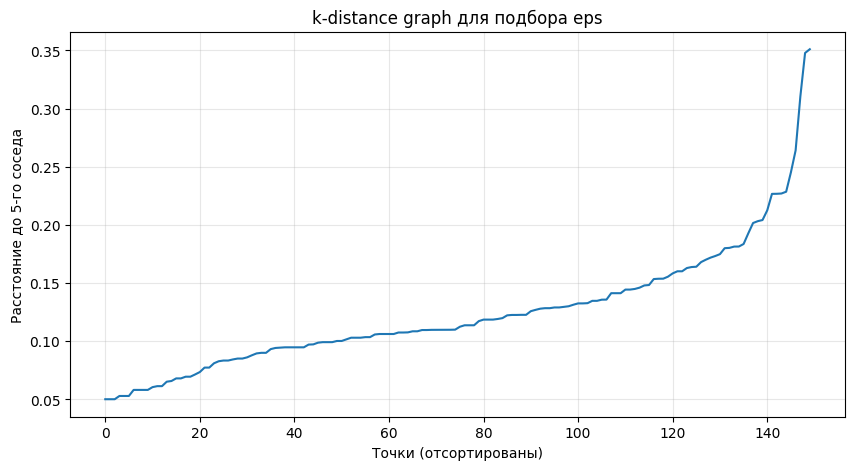

Локоть на k-distance graph — точка, где скорость роста расстояния резко меняется.
Формально — максимум второй производной или минимум первой.

Kneedle eps: 0.1813


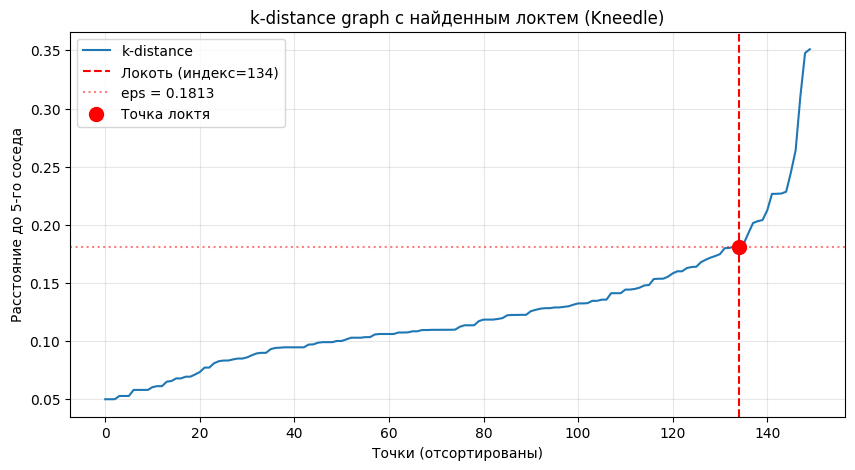

eps (ручной, максимум d²): 0.2640


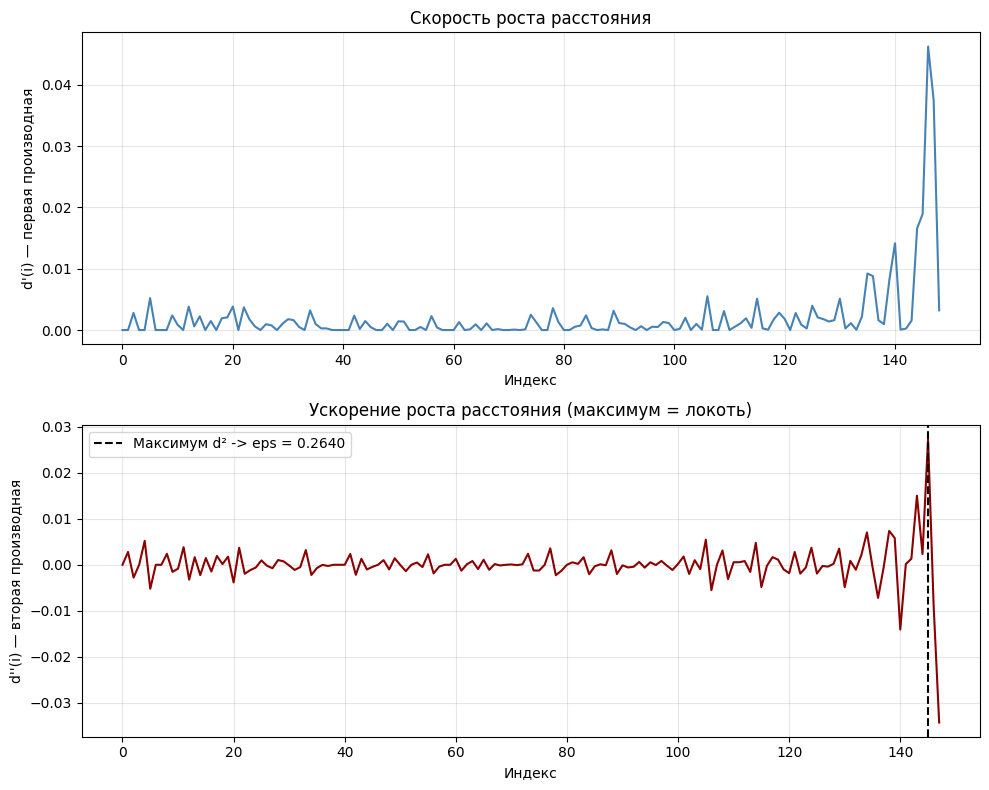

eps (уточнённое, среднее окрестности): 0.1821
eps (уточнённое, параболическая интерполяция): 0.1808

Сравнение DBSCAN при разных eps:
                 Kneedle: eps=0.1813 -> кластеров: 2, шум: 5
     среднее окрестности: eps=0.1821 -> кластеров: 2, шум: 5
                парабола: eps=0.1808 -> кластеров: 2, шум: 5
                      d²: eps=0.2640 -> кластеров: 2, шум: 1

Финальный eps: 0.2640 (метод: d²)
  кластеров: 2, шум: 1

Уникальные метки: [-1  0  1]


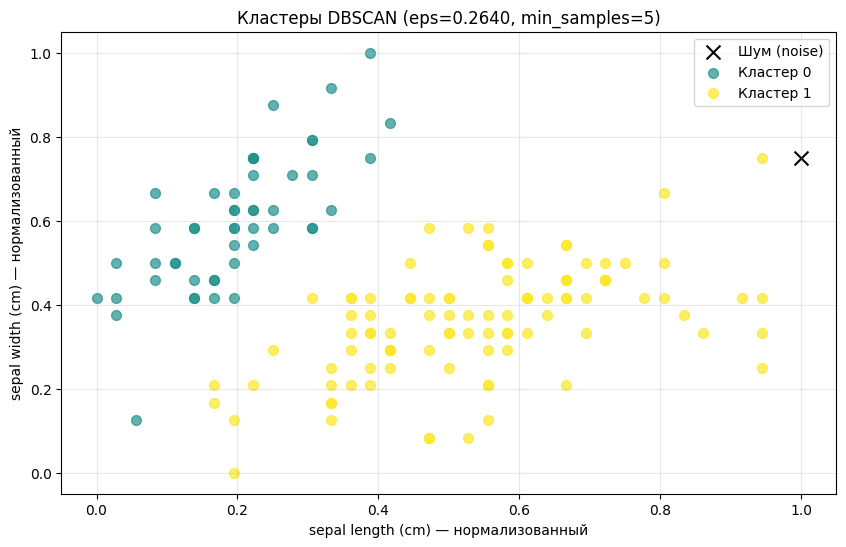

In [19]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt

# ==================== ШАГ 1: k-distance graph (как в методичке) ====================

k = 5
neighbors = NearestNeighbors(n_neighbors=k)
neighbors.fit(iris_df)
distances, _ = neighbors.kneighbors(iris_df)

distances = np.sort(distances[:, k-1], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Точки (отсортированы)')
plt.ylabel(f'Расстояние до {k}-го соседа')
plt.title('k-distance graph для подбора eps')
plt.grid(True, alpha=0.3)
plt.show()

print("Локоть на k-distance graph — точка, где скорость роста расстояния резко меняется.\n"
      "Формально — максимум второй производной или минимум первой.\n")

# ==================== ШАГ 2: автоматический метод (Kneedle) ====================

def find_knee(distances):
    n = len(distances)
    x = np.arange(n)
    y = distances
    x1, y1 = x[0], y[0]
    x2, y2 = x[-1], y[-1]
    numerator = np.abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1)
    denominator = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
    distances_to_line = numerator / denominator
    return np.argmax(distances_to_line)

elbow_idx = find_knee(distances)
eps_auto = distances[elbow_idx]
print(f"Kneedle eps: {eps_auto:.4f}")

# График с точкой локтя
plt.figure(figsize=(10, 5))
plt.plot(distances, label='k-distance')
plt.axvline(elbow_idx, color='red', linestyle='--',
            label=f'Локоть (индекс={elbow_idx})')
plt.axhline(eps_auto, color='red', linestyle=':', alpha=0.5,
            label=f'eps = {eps_auto:.4f}')
plt.scatter([elbow_idx], [eps_auto], color='red', s=100, zorder=5,
            label='Точка локтя')
plt.xlabel('Точки (отсортированы)')
plt.ylabel(f'Расстояние до {k}-го соседа')
plt.title('k-distance graph с найденным локтем (Kneedle)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==================== ШАГ 3: ручной метод через производные ====================

# Первая производная (скорость роста)
d1 = np.diff(distances)

# Вторая производная (ускорение роста)
d2 = np.diff(d1)

# Локоть — максимум второй производной
elbow_idx_d2 = np.argmax(d2) + 1
eps_d2 = distances[elbow_idx_d2]
print(f"eps (ручной, максимум d²): {eps_d2:.4f}")

# График производных с точкой локтя
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(d1, color='steelblue')
axes[0].set_xlabel('Индекс')
axes[0].set_ylabel("d'(i) — первая производная")
axes[0].set_title('Скорость роста расстояния')
axes[0].grid(True, alpha=0.3)

axes[1].plot(d2, color='darkred')
axes[1].axvline(np.argmax(d2), color='black', linestyle='--',
                label=f'Максимум d² -> eps = {eps_d2:.4f}')
axes[1].set_xlabel('Индекс')
axes[1].set_ylabel("d''(i) — вторая производная")
axes[1].set_title('Ускорение роста расстояния (максимум = локоть)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==================== ШАГ 4: уточнение eps через интерполяцию ====================

# Вариант А: среднее локтя и соседей
eps_refined_avg = np.mean(distances[max(0, elbow_idx-1):elbow_idx+2])
print(f"eps (уточнённое, среднее окрестности): {eps_refined_avg:.4f}")

# Вариант Б: параболическая интерполяция по трём точкам
i = elbow_idx
if 0 < i < len(distances) - 1:
    y0, y1, y2 = distances[i-1], distances[i], distances[i+1]
    denom = (y0 - 2*y1 + y2)
    if denom != 0:
        offset = 0.5 * (y0 - y2) / denom
        eps_refined_parabola = y1 + offset * (y2 - y0) / 2
    else:
        eps_refined_parabola = y1
else:
    eps_refined_parabola = eps_auto

print(f"eps (уточнённое, параболическая интерполяция): {eps_refined_parabola:.4f}")

# ==================== ШАГ 5: сравнение DBSCAN при разных eps ====================

print("\nСравнение DBSCAN при разных eps:")
candidates = {
    'Kneedle': eps_auto,
    'среднее окрестности': eps_refined_avg,
    'парабола': eps_refined_parabola,
    'd²': eps_d2,
}

results = []
for name, eps_test in candidates.items():
    db = DBSCAN(eps=eps_test, min_samples=5)
    lbl = db.fit_predict(iris_df)
    n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
    n_noise = (lbl == -1).sum()
    results.append((name, eps_test, n_clusters, n_noise))
    print(f"  {name:>22}: eps={eps_test:.4f} -> кластеров: {n_clusters}, шум: {n_noise}")

# ==================== ШАГ 6: выбор финального eps и кластеризация ====================

# Выбираем eps по критерию: 2-3 кластера и минимум шума
best = None
for name, eps_test, n_clusters, n_noise in results:
    if 2 <= n_clusters <= 3:
        if best is None or n_noise < best[3]:
            best = (name, eps_test, n_clusters, n_noise)

if best is None:
    # Если ни один не дал 2-3 кластеров — берём Kneedle
    best = results[0]

name_best, eps_best, n_clusters_best, n_noise_best = best
print(f"\nФинальный eps: {eps_best:.4f} (метод: {name_best})")
print(f"  кластеров: {n_clusters_best}, шум: {n_noise_best}")

dbscan_final = DBSCAN(eps=eps_best, min_samples=5)
labels = dbscan_final.fit_predict(iris_df)

print(f"\nУникальные метки: {np.unique(labels)}")

# ==================== ШАГ 7: финальная визуализация кластеров ====================

plt.figure(figsize=(10, 6))

unique_labels = np.unique(labels)
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_labels)))

for label, color in zip(unique_labels, colors):
    if label == -1:
        mask = labels == -1
        plt.scatter(iris_df.iloc[mask, 0], iris_df.iloc[mask, 1],
                    c='black', marker='x', s=100, label='Шум (noise)')
    else:
        mask = labels == label
        plt.scatter(iris_df.iloc[mask, 0], iris_df.iloc[mask, 1],
                    c=[color], s=50, alpha=0.7,
                    label=f'Кластер {label}')

plt.xlabel('sepal length (cm) — нормализованный')
plt.ylabel('sepal width (cm) — нормализованный')
plt.title(f'Кластеры DBSCAN (eps={eps_best:.4f}, min_samples=5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Постройте диаграмму рассеяния для признаков "sepal length (cm)" "sepal width (cm)", цвет точек на диаграмме должен быть различным для разных кластеров

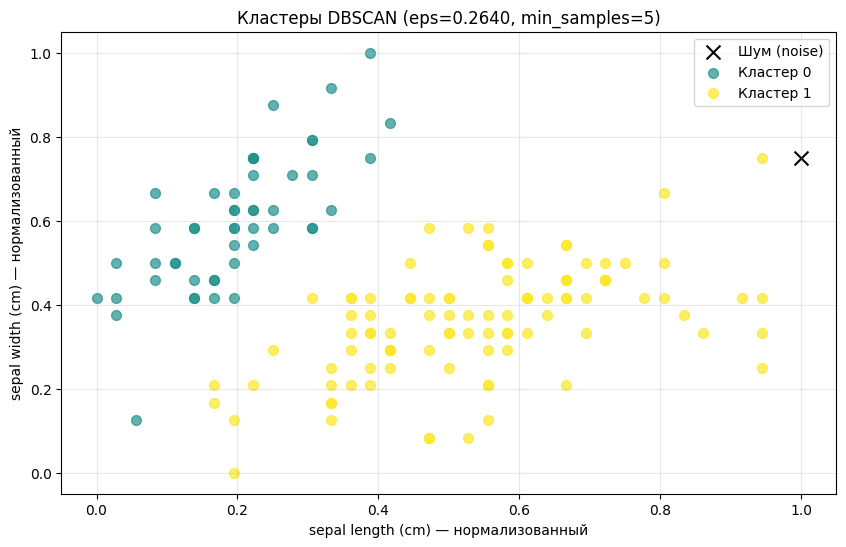

In [20]:
plt.figure(figsize=(10, 6))

unique_labels = np.unique(labels)
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_labels)))

for label, color in zip(unique_labels, colors):
    if label == -1:
        mask = labels == -1
        plt.scatter(iris_df.iloc[mask, 0], iris_df.iloc[mask, 1],
                    c='black', marker='x', s=100, label='Шум (noise)')
    else:
        mask = labels == label
        plt.scatter(iris_df.iloc[mask, 0], iris_df.iloc[mask, 1],
                    c=[color], s=50, alpha=0.7,
                    label=f'Кластер {label}')

plt.xlabel('sepal length (cm) — нормализованный')
plt.ylabel('sepal width (cm) — нормализованный')
plt.title(f'Кластеры DBSCAN (eps={eps_best:.4f}, min_samples=5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Вывод:** в ходе выполнения лабораторной работы освоены методы кластеризации — обучения без учителя, при котором алгоритм сам находит группы похожих объектов без размеченных данных. На наборе «Ирисы Фишера» выполнена нормализация признаков и применён алгоритм DBSCAN, для которого параметр eps подобран несколькими способами: по k-distance graph, методом Kneedle и через дискретные производные (анализ критических точек). Сравнение методов дало устойчивое значение eps ≈ 0.26, при котором DBSCAN находит 2 кластера и 1 шумовую точку — это показывает, что вид setosa чётко отделим, а versicolor и virginica образуют одно плотное облако. Построена диаграмма рассеяния с раскраской точек по кластерам, подтверждающая результат; кластеризация позволяет исследовать структуру данных и находить скрытые группы и аномалии без заранее известных меток.

**Ответы на контрольные вопросы:**

**В чем состоит задача кластеризации?**

Задача кластеризации: разбить множество объектов на группы (кластеры) так, чтобы объекты внутри одной группы были максимально похожи, а между группами — максимально различны. Метки классов заранее неизвестны — это обучение без учителя.

**Для каких целей используется кластеризацияия?**

Для каких целей используется: сегментация клиентов, поиск аномалий и выбросов, сжатие и снижение размерности, группировка документов/товаров, предварительный анализ данных перед классификацией, обнаружение скрытых структур.

**Алгоритм кластеризации Ллойда.**

Алгоритм Ллойда (K-средних): 1) случайно инициализировать K центроидов; 2) отнести каждую точку к ближайшему центроиду; 3) пересчитать центроиды как среднее точек своего кластера; 4) повторять шаги 2–3, пока центроиды не перестанут смещаться (или не достигнут лимита итераций). Минимизирует сумму квадратов расстояний точек до своих центроидов.

**Как выбрать количество кластеров для алгоритма K-средних**

Как выбрать K для K-средних: метод локтя (график inertia vs K — искать точку перегиба), метод силуэта (максимизировать средний silhouette score), индекс Калински-Харабаса, или априорное знание предметной области.

**Алгоритм DBSCAN**

Алгоритм DBSCAN: для каждой точки считает число соседей в радиусе eps. Если соседей ≥ min_samples — точка core (ядро). Core-точки, достижимые друг от друга, образуют кластер; граничные точки в радиусе eps от core добавляются в кластер; остальные помечаются как шум (-1). Находит кластеры произвольной формы, не требует задавать число кластеров, устойчив к выбросам.